### Anna Horton - Automated Atlas Homework
ONYEN: arhorton <br>
PID: 730664552

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages 

<Axes: >

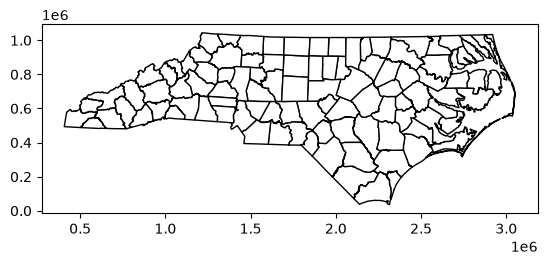

In [2]:
# getting the US census data
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 

## Code for county level data for North Carolina (STATEFP = 37)
counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

In [7]:
## importing my vector layer for my automated atlas
nursing_homes = gpd.read_file("Nursing_Homes.geojson")

## getting a good look at my data
nursing_homes.head()
nursing_homes.columns

## the columns that I likely need to keep are: id, name, county, fips, beds, geometry
nursing_homes = nursing_homes[["id", "name", "county", "fips", "beds", "geometry"]]

In [21]:
## putting a spatial join between the counties info and the nursing_homes info (I just realized that I need this for the information printing later)
## I also need to make a columnn that has the total beds (beds + excs_beds) from the nursing_home variable

counties = gpd.sjoin(nc_counties, nursing_homes, how = "left")
counties.head()

/var/folders/gr/m2n_2p5571g1k1fldyhfmx980000gn/T/ipykernel_74787/3432093001.py:4: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:6543
Right CRS: EPSG:4326

  counties = gpd.sjoin(nc_counties, nursing_homes, how = "left")


,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry,index_right,id,name,county,fips,beds
90,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,"POLYGON ((1978481.879 199930.366, 1979179.073 ...",NaN,NaN,NaN,NaN,NaN,NaN
91,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,"POLYGON ((408779.421 505506.597, 408786.42 505...",NaN,NaN,NaN,NaN,NaN,NaN
92,37,149,01008579,0500000US37149,37149,Polk,Polk County,NC,North Carolina,06,615606325,1964035,"POLYGON ((997042.881 555579.496, 997049.933 55...",NaN,NaN,NaN,NaN,NaN,NaN
93,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,"POLYGON ((1193571.583 980437.246, 1194562.461 ...",NaN,NaN,NaN,NaN,NaN,NaN
94,37,055,01026133,0500000US37055,37055,Dare,Dare County,NC,North Carolina,06,992558552,3000513281,"MULTIPOLYGON (((2968803.433 811517.819, 297128...",NaN,NaN,NaN,NaN,NaN,NaN


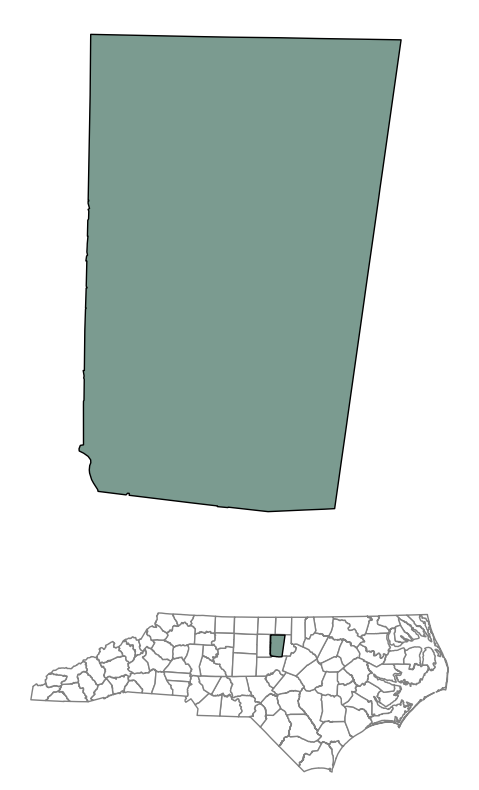

In [9]:
## this function pulls out the map of only the county
def county_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()

## this code prints out the plot of the entire state of NC and highlights a specific county, whatever is passed as the parameter to the function originally
def locator_map(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]
    nc_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()

## putting them together - this will be a page of the atlas, at its most basic
fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 10),
    gridspec_kw={"height_ratios": [3, 1]}
)

county_map("Orange", axes[0])
locator_map("Orange", axes[1])

plt.show()

def county_figure(county):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    fig.savefig(f"{county}_County.pdf")
    plt.close(fig)

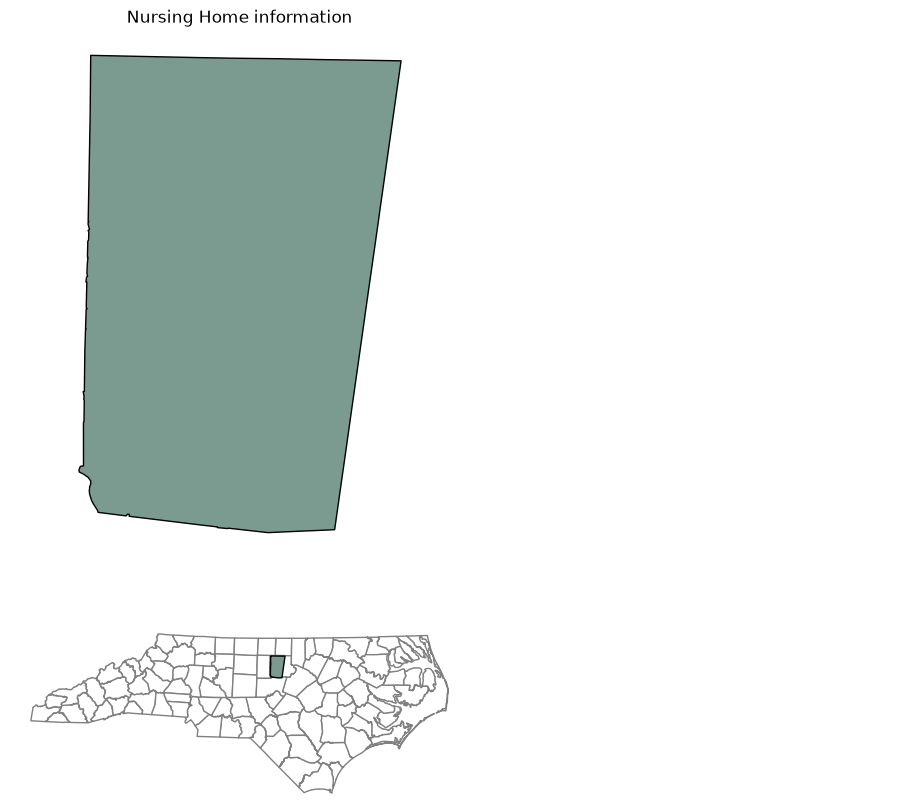

In [11]:
## Moving the pages around so that I can add additional information on the sides of the page
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Orange", axes[0, 0])
locator_map("Orange", axes[1, 0])
axes[0, 0].set_title("Nursing Home information")

for ax in axes.flat:
    ax.set_axis_off()

In [ ]:
## this is the code that will allow me to print out a little bit more about the county onto the atlas pages
def county_info(county, ax):
    selected = nc_counties[nc_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    land_km2 = land / 1_000_000
    water_km2 = water / 1_000_000

    land_mi2 = land / 2_589_988.110336
    water_mi2 = water / 2_589_988.110336

    ax.text(
        0.1, 0.8,
        f"LAND\n{land_km2:,.2f} km²\n{land_mi2:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="olivedrab",
        va="top"
    )

    ax.text(
        0.1, 0.4,
        f"WATER\n{water_km2:,.2f} km²\n{water_mi2:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="steelblue",
        va="top"
    )

    ax.set_axis_off()

In [ ]:
## here is the code that will put all of the pages into a PDF

def county_figure(county, pdf):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    pdf.savefig(fig)
    plt.close(fig)

with PdfPages("NC_Counties.pdf") as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in nc_counties["NAME"]:
        county_figure(county, pdf)